<a href="https://colab.research.google.com/github/sofiyapriz/Lab1_GroupProject/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22%D0%9B%D0%A08_%D0%9C%D0%9D_%D0%9F%D1%80%D0%B8%D0%B7_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris_data = load_iris()
features_df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
print("Перші 5 рядків набору даних Iris:")
display(features_df.head())

Перші 5 рядків набору даних Iris:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

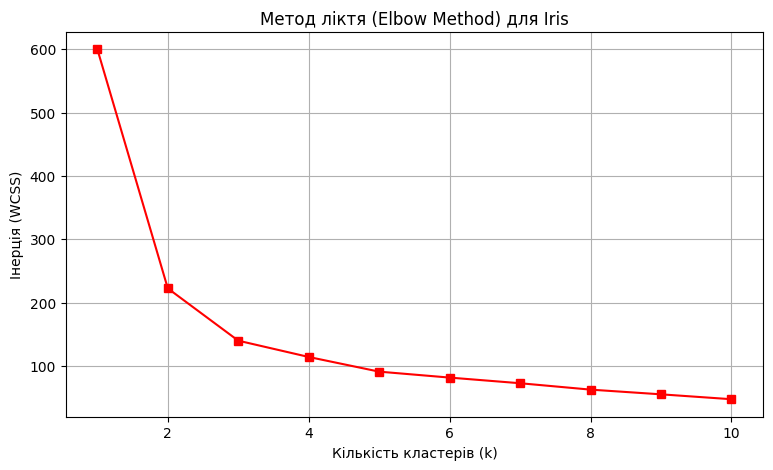

In [ ]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(iris_data.data)
scaled_df = pd.DataFrame(scaled_features, columns=iris_data.feature_names)

inertia_values = []
k_range = range(1, 11)

for k in k_range:
    kmeans_model = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans_model.fit(scaled_df)
    inertia_values.append(kmeans_model.inertia_)

# Побудова графіка методу ліктя
plt.figure(figsize=(9, 5))
plt.plot(k_range, inertia_values, marker='s', color='r', linestyle='-')
plt.title('Метод ліктя (Elbow Method) для Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (WCSS)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

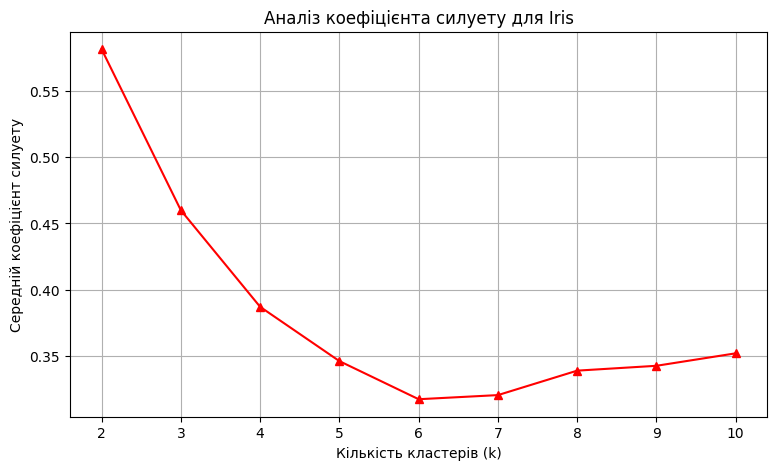

In [ ]:
sil_scores = []
cluster_range = range(2, 11)

for k in cluster_range:
    kmeans_model = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans_model.fit_predict(scaled_df)
    score = silhouette_score(scaled_df, cluster_labels)
    sil_scores.append(score)

# Побудова графіка силуетів
plt.figure(figsize=(9, 5))
plt.plot(cluster_range, sil_scores, marker='^', color='r', linestyle='-')
plt.title('Аналіз коефіцієнта силуету для Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

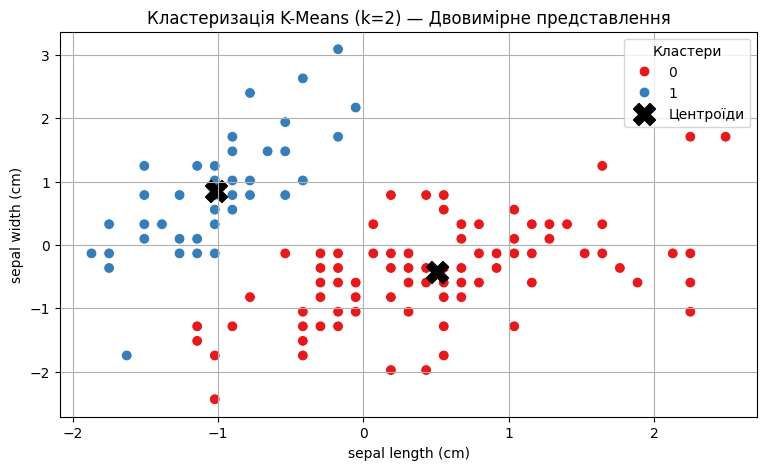

In [ ]:
optimal_k = 2
final_kmeans = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, n_init=10, random_state=42)
assigned_clusters = final_kmeans.fit_predict(scaled_df)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    x=scaled_df.iloc[:, 0],
    y=scaled_df.iloc[:, 1],
    hue=assigned_clusters,
    palette='Set1',
    legend='full',
    s=60
)

# Відображення центроїдів
centroids = final_kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=250,
    c='black',
    marker='X',
    label='Центроїди'
)

plt.title(f'Кластеризація K-Means (k={optimal_k}) — Двовимірне представлення')
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])
plt.legend(title='Кластери')
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

**Метод ліктя** та **метод силуетів** узгоджено вказують на те, що оптимальна кількість кластерів для набору даних Iris дорівнює двом (k = 2).

Обидва методи чудово доповнюють один одного:

* **Метод ліктя** вказує на те, в якому випадку подальше збільшення кількості кластерів призводить до незначного покращення компактності даних (на графіку інерції з'являється характерний злам).
* **Метод силуетів** оцінює якість і чіткість розділення точок на дві укрупнені групи, показуючи найвище значення середнього коефіцієнта силуету саме при k = 2.

Отримані графіки повністю збігаються з цим вибором.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print("Назви стовпців")
df.columns

Назви стовпців


Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print("Перевірка на пропущені значення:")
df.isnull().sum()

Перевірка на пропущені значення:


,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print("Перевірка наявності дублікатів:")
df.duplicated().sum()

Перевірка наявності дублікатів:


np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
print("Описова статистика:")
df.describe()

Описова статистика:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Розмір навчальної вибірки: {X_train.shape}, тестової: {X_test.shape}")

Розмір навчальної вибірки: (1913, 13), тестової: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
# Параметри для пошуку
param_grid_rf = {
    'n_estimators': [50, 100, 200, 300, 500],  # 100 - дефолтне значення
    'max_depth': [None, 5, 10, 20, 30],         # None - дефолтне значення
    'min_samples_split': [2, 5, 10],            # 2 -  дефолтне значення
    'min_samples_leaf': [1, 2, 4],              # 1 - дефолтне значення
}

# Модель
rf = RandomForestClassifier(random_state=42)

# GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=rf, param_grid=param_grid_rf, cv=5, n_jobs=-1, verbose=2
)
grid_search_rf.fit(X_train, y_train)

# Найкращі параметри та точність
print("Найкращі параметри для Random Forest:", grid_search_rf.best_params_)
print("Максимальна точніть моделі Random Forest за результатами крос-валідації:", grid_search_rf.best_score_)

# Оцінка на тестовій вибірці
y_pred_rf = grid_search_rf.predict(X_test)
print("Точність тестування для Random Forest:", accuracy_score(y_test, y_pred_rf))

Fitting 5 folds for each of 225 candidates, totalling 1125 fits
Найкращі параметри для Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Максимальна точніть моделі Random Forest за результатами крос-валідації: 0.9210709061829316
Точність тестування для Random Forest: 0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
# Параметри для пошуку без несумісних комбінацій
param_grid_lr = [
    {
        'penalty': ['l1', 'l2'], # 'l2' - дефолтне значення
        'C': [0.001, 0.01, 0.1, 1, 10, 100], # 1.0 - дефолтне значення
        'solver': ['saga'],  # saga підтримує і l1, і l2
    },
    {
        'penalty': ['l2'], # 'l2' - дефолтне значення
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'solver': ['lbfgs'],  # 'lbfgs' -  дефолтне значення, яке  підтримує лише l2
    },
]

# Модель
lr = LogisticRegression(random_state=42, max_iter=1000)

# GridSearchCV
grid_search_lr = GridSearchCV(
    estimator=lr, param_grid=param_grid_lr, cv=5, n_jobs=-1, verbose=2
)
grid_search_lr.fit(X_train, y_train)

# Найкращі параметри та точність
print('Найкращі параметри для Logistic Regression:', grid_search_lr.best_params_)
print(
    'Максимальна точність моделі логістичної регресії за результатами'
    f' крос-валідації: {grid_search_lr.best_score_}'
)

y_pred_lr = grid_search_lr.predict(X_test)
print(
    'Точність тестування для Logistic Regression:'
    f' {accuracy_score(y_test, y_pred_lr)}'
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Найкращі параметри для Logistic Regression: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Максимальна точність моделі логістичної регресії за результатами крос-валідації: 0.8024113843588097
Точність тестування для Logistic Regression: 0.8183716075156576


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
# Параметри для пошуку
param_grid_svm = {
    'C': [0.1, 1, 10, 100, 1000],               # 1.0 - дефолтне значення
    'gamma': ['scale', 'auto', 1, 0.1, 0.01, 0.001], # 'scale' - дефолтне значення
    'kernel': ['rbf', 'linear', 'poly']         # 'rbf' - дефолтне значення
}

# Модель
svm = SVC(random_state=42)

# GridSearchCV
grid_search_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    n_jobs=-1,
    verbose=2
)
grid_search_svm.fit(X_train, y_train)

# Найкращі параметри та точність
print("Найкращі параметри для SVM:", grid_search_svm.best_params_)
print("Максимальна точність моделі SVM, отримана за результатами перехресної перевірки (Cross-Validation):", grid_search_svm.best_score_)

# Оцінка на тестовій вибірці
y_pred_svm = grid_search_svm.predict(X_test)
print("Точність тестування для SVM:", accuracy_score(y_test, y_pred_svm))

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Найкращі параметри для SVM: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Максимальна точність моделі SVM, отримана за результатами перехресної перевірки (Cross-Validation): 0.854677183437453
Точність тестування для SVM: 0.8496868475991649


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
y_pred_rf = grid_search_rf.predict(X_test)

print("Точність на тестовій вибірці для Random Forest:", accuracy_score(y_test, y_pred_rf))
print("Точність на тестовій вибірці для Logistic Regression:", accuracy_score(y_test, y_pred_lr))
print("Точність на тестовій вибірці для SVM:", accuracy_score(y_test, y_pred_svm))

cv_models = {
    'Random Forest': grid_search_rf,
    'Logistic Regression': grid_search_lr,
    'SVM': grid_search_svm
}

best_name = max(
    cv_models,
    key=lambda name: cv_models[name].best_score_
)

print('\nНайкраща модель за крос-валідацією:', best_name)
print('Звіт класифікації (Classification Report) для моделі:', best_name)
print(classification_report(y_test, cv_models[best_name].predict(X_test)))

Точність на тестовій вибірці для Random Forest: 0.9102296450939458
Точність на тестовій вибірці для Logistic Regression: 0.8183716075156576
Точність на тестовій вибірці для SVM: 0.8496868475991649

Найкраща модель за крос-валідацією: Random Forest
Звіт класифікації (Classification Report) для моделі: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

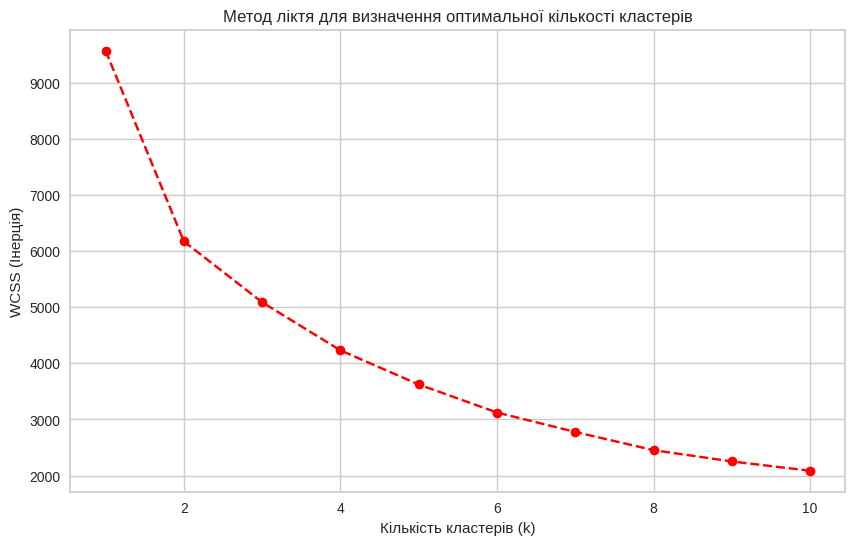

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Вибір числових стовпців для кластеризації
features = df[['Age', 'StudyTimeWeekly', 'Absences', 'GPA']]

# Масштабування даних
scaler = StandardScaler()
X_student_scaled = scaler.fit_transform(features)

# Метод ліктя (WCSS)
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_student_scaled)
    wcss.append(kmeans.inertia_)

# Візуалізація графіка ліктя (червона лінія)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', color='red', linestyle='--')
plt.title('Метод ліктя для визначення оптимальної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Інерція)')
plt.grid(True)
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

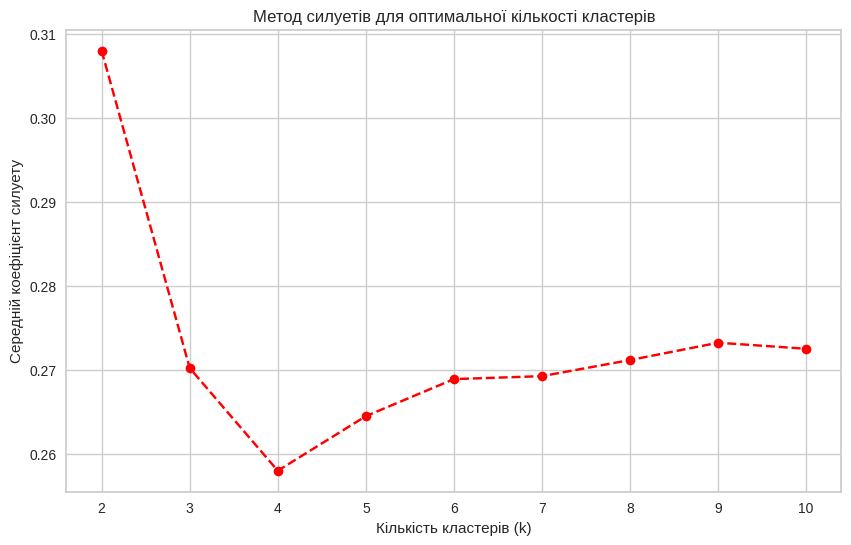

In [ ]:
# Метод силуетів для k від 2 до 10
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(X_student_scaled)
    silhouette_avg = silhouette_score(X_student_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Візуалізація графіка методу силуетів (червона лінія)
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', color='red', linestyle='--')
plt.title('Метод силуетів для оптимальної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуету')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
%pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
x_all = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
x_all_scaled = StandardScaler().fit_transform(x_all)
pca = PCA(random_state=42).fit(x_all_scaled)
pve = pca.explained_variance_ratio_

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

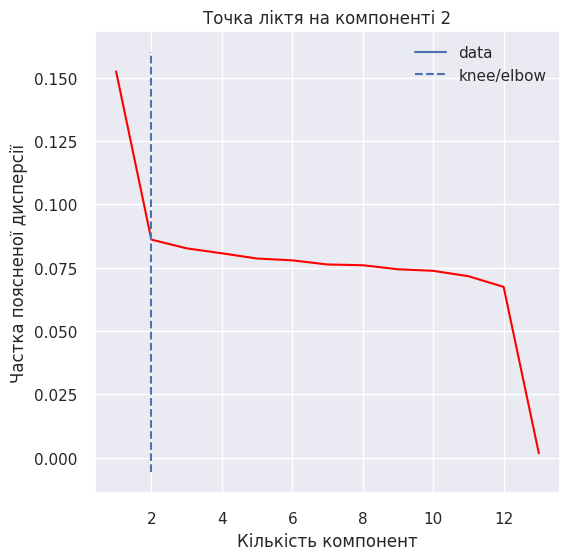

In [ ]:
sns.set_theme()

kneedle = KneeLocator(
    x=range(1, len(pve) + 1),
    y=pve,
    curve='convex',
    direction='decreasing'
)

# Візуалізація
kneedle.plot_knee()

plt.gca().lines[0].set_color('red')
plt.title(f'Точка ліктя на компоненті {kneedle.elbow}' if kneedle.elbow is not None else 'Точку ліктя не знайдено')
plt.xlabel('Кількість компонент')
plt.ylabel('Частка поясненої дисперсії')
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

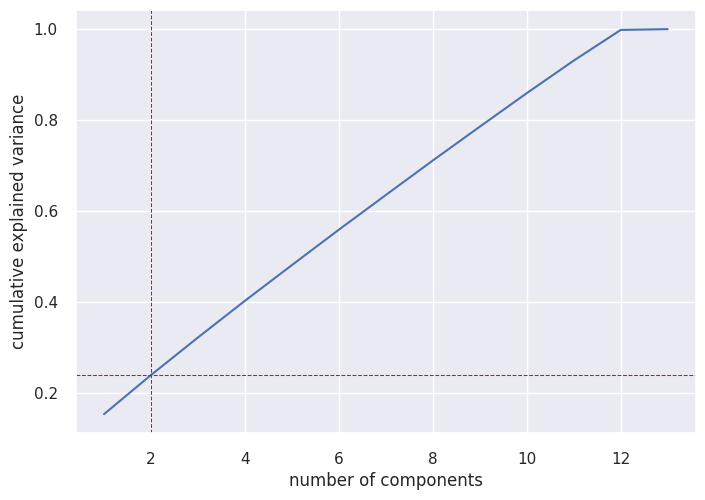

2 компонент пояснюють 23.86% дисперсії.


In [ ]:
n_components = kneedle.elbow

if n_components is None:
  n_components = len(pve)
  print('Точку ліктя не знайдено: залишаємо всі головні компоненти.')

cumulative_variance = np.cumsum(pve)
ax = sns.lineplot(x=range(1, len(pve) + 1), y=cumulative_variance)

ax.axvline(x=n_components, c='red', linestyle='--', linewidth=0.75)
ax.axhline(y=cumulative_variance[n_components - 1], c='red', linestyle='--', linewidth=0.75)
ax.set(xlabel='number of components', ylabel='cumulative explained variance')
plt.grid(True)
plt.show()

print(f'{n_components} компонент пояснюють {cumulative_variance[n_components - 1]:.2%} дисперсії.')
X_pca = pca.transform(x_all_scaled)[:, :n_components]

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

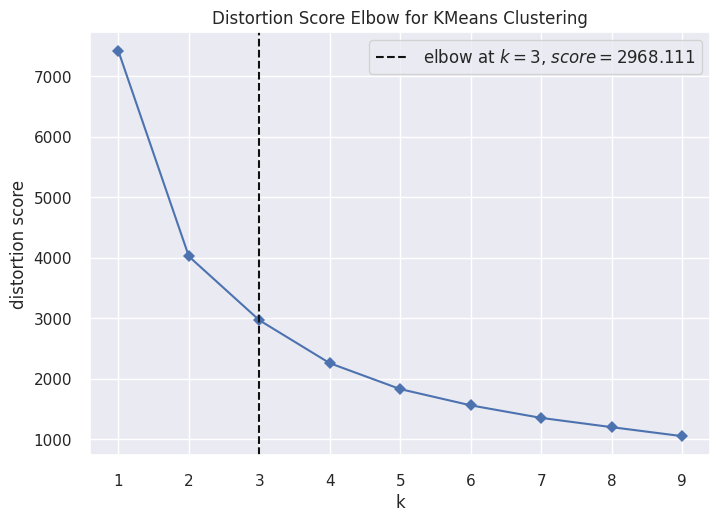

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
model_kmn = KMeans(n_init=10, random_state=42)

visualizer = KElbowVisualizer(
    model_kmn,
    k=(1, 10),
    timings=False
)

visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

1. У датасеті багато показників одночасно, а за допомогою аналізу головних компонент (PCA) ми зменшуємо цю кількість характеристик студентів до двох головних показників (двох осей координат), які несуть у собі найголовнішу інформацію. А метод ліктя допомагає визначити оптимальну кількість груп (кластерів) для студентів, тоді як метод силуетів перевіряє якість цього поділу та показує, наскільки чітко студенти сформували свої групи.

2. **Різниця між класифікацією за GradeClass і кластеризацією**:

* **Класифікація** — це навчання з учителем (Supervised Learning). Вона використовує цільову змінну (GradeClass), тобто алгоритм заздалегідь знає «правильні» відповіді (класи успішності студентів) і будується на мінімізації помилок прогнозування цього класу.

* **Кластеризація **— це навчання без учителя (Unsupervised Learning). Вона працює без цільової змінної (GradeClass не використовується). Алгоритм самостійно групує об'єкти на основі їхньої схожості та близькості за іншими числовими ознаками (наприклад, вік, час навчання, пропуски, GPA), не знаючи заздалегідь жодних класів чи міток.

3. **Результати PCA**:
* Кількість обраних головних компонент: 2
* 2 компонент пояснюють 23.86% дисперсії.